In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import sys
import time
sys.path.append('./FUNCIONES')
sys.path.append("imagenEntrada")

# PRÁCTICA 5 Simulación y Filtrado de Ruidos en Imágenes

Objetivo: simulación y filtrado de ruidos en imágenes; evaluación de distintos tipos y
opciones de filtrado. 

La práctica se ha dividido en tres partes:

1. **Primera parte**: simulación de ruidos tipo gaussiano y sal y pimienta.

2. **Segunda parte**: implementación de filtros gaussiano, mediana y adaptativo.

3. **Tercera parte**: evaluación de eficiencia de filtros gaussiano, mediana y adaptativo.


## PRIMERA PARTE: Simulación de ruidos.

1. 1. Lee la imagen en escala de gris “img.png”.

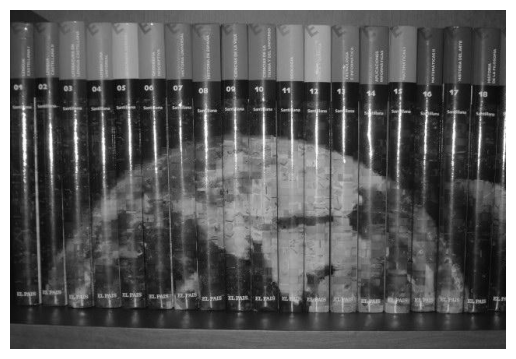

(436, 637)

In [3]:
I = cv2.imread("imagenEntrada/img.png")

I = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

plt.imshow(I, cmap="gray")
plt.axis("off")
plt.show()



I.shape

2. Corrompe la imagen anterior con ruido de tipo de sal y pimienta y de tipo gaussiano para
generar imágenes ruidosas, tal y como se describe a continuación:

a. Sal y pimienta, con p = 0.9 y q = 0.95 (ver ecuación). La imagen corrompida con este
ruido (imagen A) se calculará de la siguiente manera:

```md
            [I(i,j)     x < p] siendo I la imagen original sin corromper, x una variable aleatoria uniforme de rango (0,1)
A(i, j) =   [0     p <= x < q] q-p el porcentaje de pixeles con ruido tipo pimienta
            [255   q <= x < 1] y 1-q el porcentaje de ruido de tipo sal
```

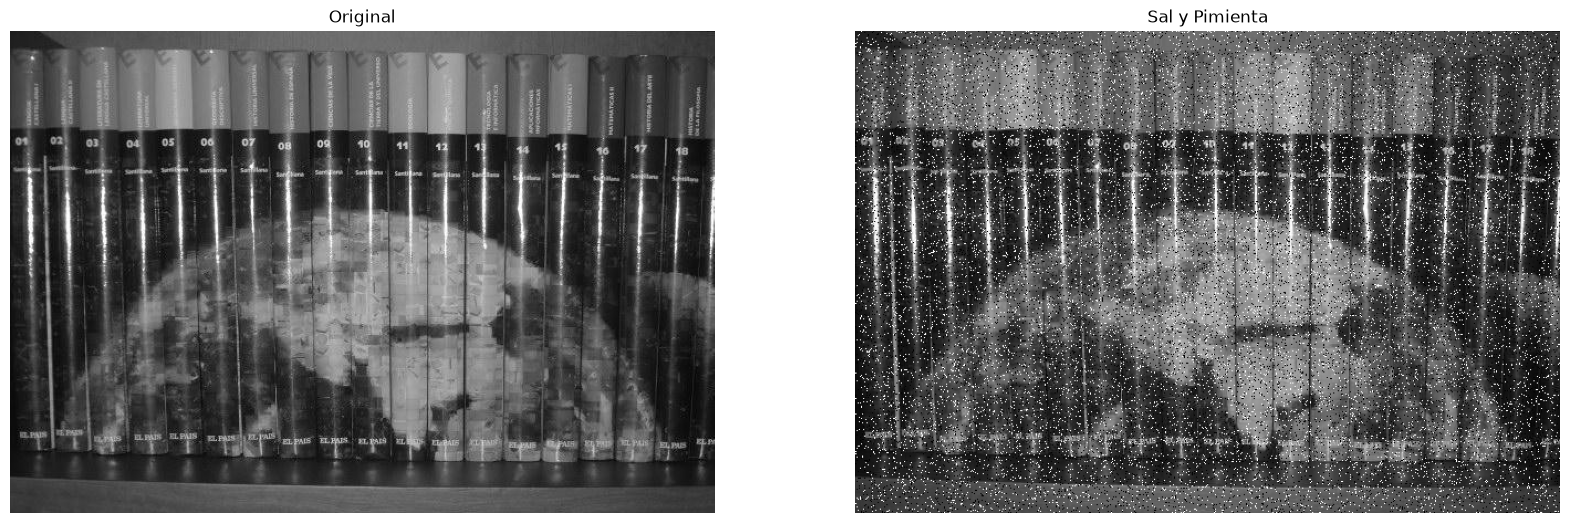

In [4]:
alto, ancho = I.shape

np.random.seed(14)

matriz_rnd = np.random.random((alto, ancho))
p = 0.9
q = 0.95

SyP = I.copy()

SyP[(matriz_rnd >= p) & (matriz_rnd < q)] = 0
SyP[matriz_rnd >= q]  = 255

plt.figure(figsize=(20,10))
plt.subplot(1,2,1)
plt.imshow(I, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(SyP, cmap="gray")
plt.title("Sal y Pimienta")
plt.axis("off")

plt.show()

b. Gaussiano de media nula y desviación típica 5, 10, 35 y 50. 

**Apunte teórico**

Sea N(0,1) una función distribución de probabilidad normal o gaussiana de media cero y varianza 1
(N(0,1)). Utilizando esta distribución, se puede obtener otra distribución gaussiana de media u y varianza σ^2(N(u, σ^2)):

```md
            N (u,σ^2) - u
N(0,1) = ___________________
                σ
```


In [5]:
alto, ancho = I.shape
media = 0
desviaciones = np.array([5, 10, 35, 50])

Gaussianos = np.zeros((alto, ancho, len(desviaciones)), dtype=np.uint8)
np.random.seed(14)

for i in range(len(desviaciones)):
    ruido =  np.random.normal(media, desviaciones[i], I.shape)
    G = np.clip(np.round(I.astype(np.float32) + ruido), 0, 255).astype(np.uint8)
    Gaussianos[:,:,i] = G


3. Visualiza la imagen original y las 5 imágenes ruidosas generadas (en una misma ventana
gráfica).


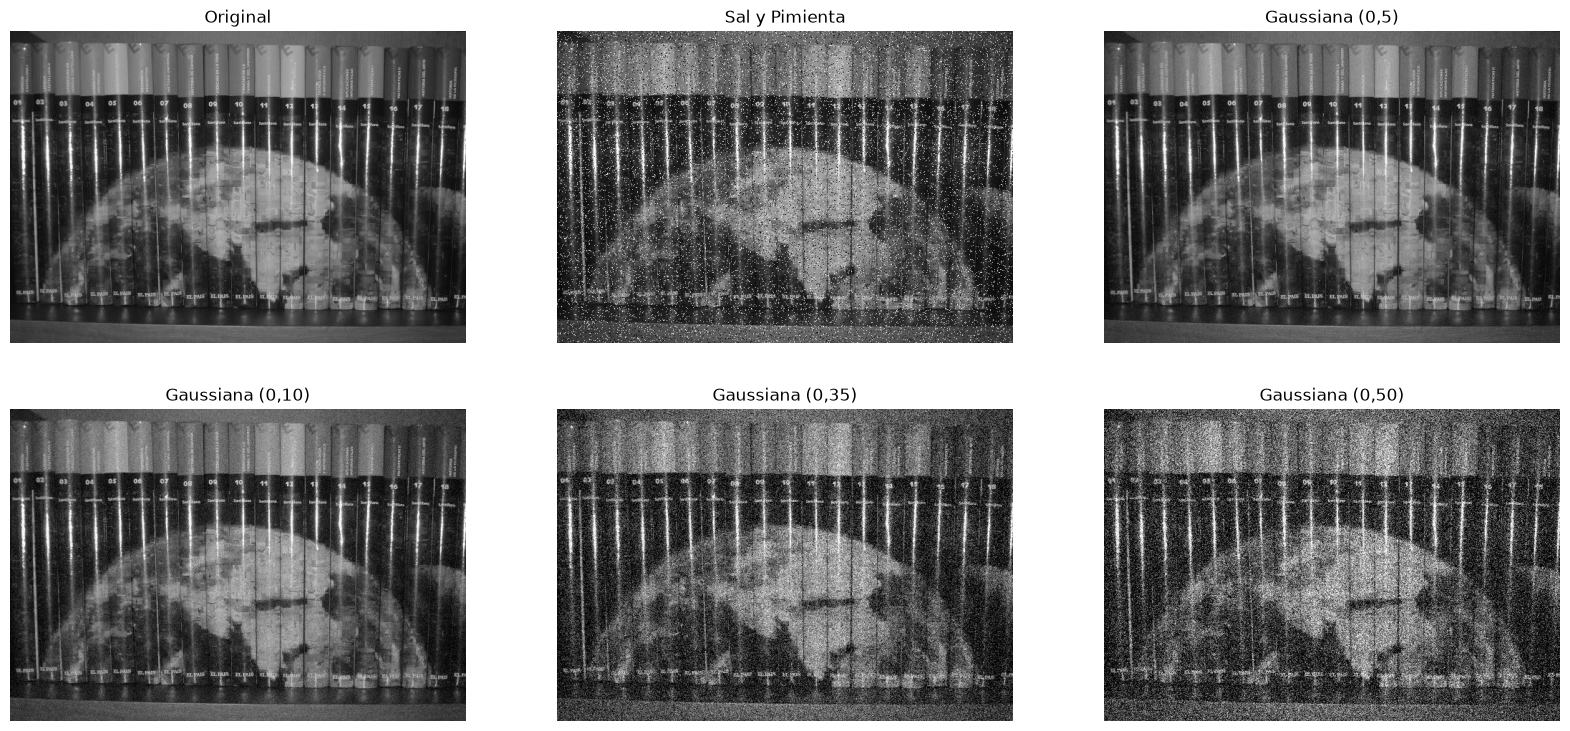

In [6]:
titulos = ["Original", "Sal y Pimienta", "Gaussiana (0,5)", "Gaussiana (0,10)", "Gaussiana (0,35)", "Gaussiana (0,50)"]
imagenes = [I, SyP, Gaussianos[:,:,0], Gaussianos[:,:,1], Gaussianos[:,:,2], Gaussianos[:,:,3]]
plt.figure(figsize=(20,9))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imagenes[i], cmap="gray")
    plt.title(titulos[i])
    plt.axis("off")

plt.show()

4. Representa en un mismo gráfico la variación de los niveles de gris a lo largo de la línea
horizontal central para la imagen original, para la imagen contaminada con ruido de tipo
sal y pimienta, y para la imagen corrompida con ruido gaussiano de desviación típica 10.
Observa las distintas distribuciones del ruido.

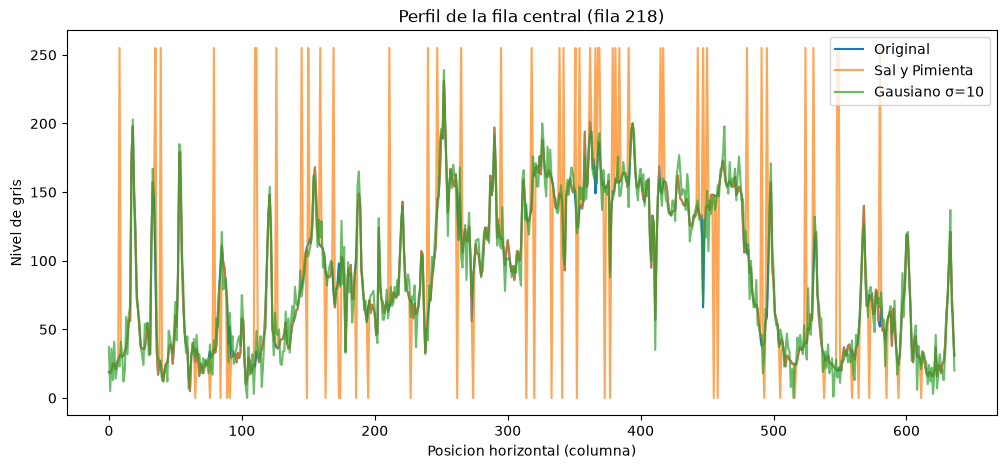

In [38]:
alto, ancho = I.shape

fila = alto // 2

plt.figure(figsize=(12,5))
plt.plot(I[fila,:], label="Original")
plt.plot(SyP[fila, :], label="Sal y Pimienta", alpha=0.7)
plt.plot(Gaussianos[fila, :, 1], label="Gausiano σ=10", alpha=0.7)

plt.xlabel("Posicion horizontal (columna)")
plt.ylabel("Nivel de gris")
plt.title(f'Perfil de la fila central (fila {fila})')
plt.legend()
plt.show()

5. En un directorio de Imágenes Generadas, almacena la imagen corrompida con ruido sal y
pimienta y las cuatro imágenes corrompidas con ruidos gaussiano (media nula y
desviaciones típicas 5, 10, 35 y 50).

In [39]:

cv2.imwrite("ImagenesGeneradas/syp.png", SyP)
cv2.imwrite("ImagenesGeneradas/g5.png", Gaussianos[:,:,0])
cv2.imwrite("ImagenesGeneradas/g10.png", Gaussianos[:,:,1])
cv2.imwrite("ImagenesGeneradas/g35.png", Gaussianos[:,:,2])
cv2.imwrite("ImagenesGeneradas/g50.png", Gaussianos[:,:,3])

True

**Objetivo teórico**: conocer los dos tipos de ruido, su forma de manifestarse en imágenes
digitales y saber cómo se pueden simular e implementar

## SEGUNDA PARTE: Implementación de filtros gaussiano, mediana y adaptativo.

### 2.1.-Filtro Gaussiano

a. Implementación de kernel de convolución de un filtro gaussiano (este apartado debe
realizarse en un cuaderno Jupyter independiente)

-  Crea la máscara del filtro gaussiano 5x5, considerando la relación W = 5 σ (siendo σ la
desviación típica del filtro y W sus dimensiones), utilizando el siguiente código
(programación vectorizada sin bucles):

```md
W = 5; sigma = W/5
mitad = int(W//2)
X = np.arange(-mitad, mitad + 1)
Y = np.arange(-mitad, mitad + 1)
X2, Y2 = np.meshgrid(X, Y)
hg = np.exp(-0.5 * (X2**2 + Y2**2) / (sigma**2))
hg = hg / np.sum(hg)
```

- Crea la misma máscara, pero implementando un doble bucle for para generar cada uno
de sus valores. 

- Utiliza la función de OpenCV getGaussianKernel para generar los valores de la
máscara y comprueba que se obtienen los mismos resultados en los tres casos (pueden
asumirse diferencias máximas del orden de 10^(-8) ).


**Observacion:**

getGaussianKernel devuelve un vector columna; se debe multiplicar este vector por su
traspuesto para obtener la máscara 2D:

gk = cv2.getGaussianKernel(W, sigma); hg = gk @ gk.T

- Visualiza la máscara en una representación de superficie 3D utilizando el siguiente
código:

```md
W = hg.shape[0]
mitad = W//2
X = np.arange(-mitad, mitad + 1); Y = np.arange(-mitad, mitad + 1)
X2, Y2 = np.meshgrid(X, Y)
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X2, Y2, hg, cmap='viridis')
ax.set_title('Máscara Gaussiana 3D')
plt.show()
```


vec vs bucle: 0.0
vec vs cv   : 1.734723475976807e-18
bucle vs cv : 1.734723475976807e-18
¿iguales?   : True
Suma de la máscara: 1.0


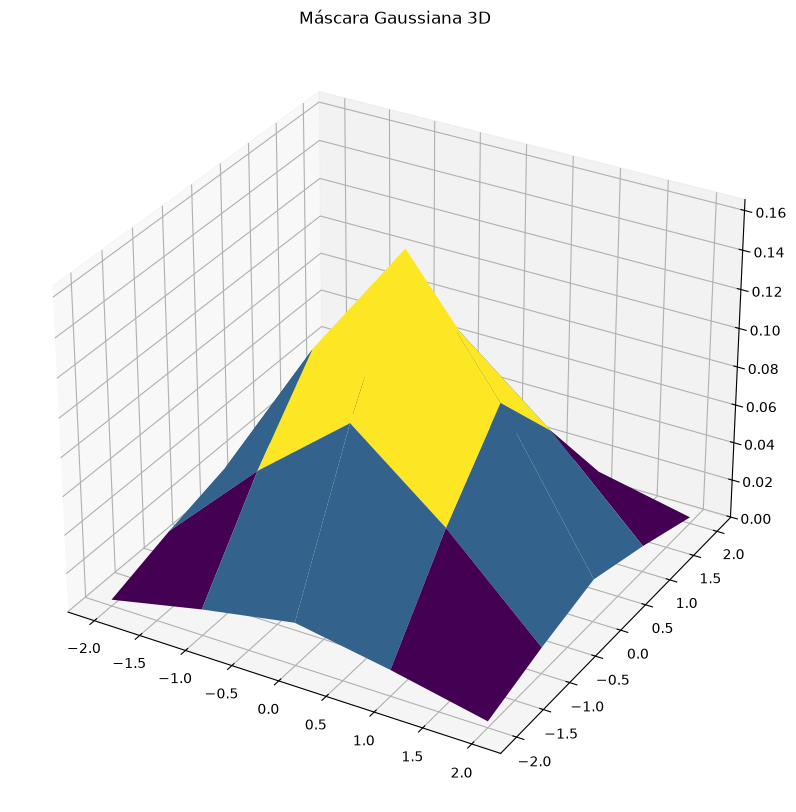

In [43]:
W = 5; sigma = W/5
mitad = int(W//2)

# 1) Vectorizada
X = np.arange(-mitad, mitad + 1)
Y = np.arange(-mitad, mitad + 1)
X2, Y2 = np.meshgrid(X,Y)
hg_vec =np.exp(-0.5 * (X2**2 + Y2**2) / (sigma**2))
hg_vec = hg_vec / np.sum(hg_vec)

# 2) Doble bucle
hg_bucle = np.zeros((W,W))
for i in range(W):
    for j in range(W):
        x = j - mitad          # columna -> x
        y = i - mitad          # fila    -> y
        hg_bucle[i, j] = np.exp(-0.5 * (x**2 + y**2) / (sigma**2))
hg_bucle = hg_bucle / np.sum(hg_bucle)

# 3) OpenCV
gk = cv2.getGaussianKernel(W, sigma)
hg_cv = gk @ gk.T

# Comprobación
print("vec vs bucle:", np.max(np.abs(hg_vec - hg_bucle)))
print("vec vs cv   :", np.max(np.abs(hg_vec - hg_cv)))
print("bucle vs cv :", np.max(np.abs(hg_bucle - hg_cv)))
print("¿iguales?   :", np.allclose(hg_vec, hg_bucle, atol=1e-8) and
                       np.allclose(hg_vec, hg_cv, atol=1e-8))
print("Suma de la máscara:", hg_vec.sum())

#3D
fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X2, Y2, hg_vec, cmap='viridis')
ax.set_title('Máscara Gaussiana 3D')
plt.show()